In [1]:
from scripts.general_nn import generalNN
from scripts import plots

In [2]:
from dataclasses import replace

from scripts.general_nn import generalNN
from scripts.settings import Settings
from scripts import plots


# Use a small training budget for this first experiment.
settings = Settings(
    warmup_updates=100,
    continuation_updates=100,
    number_of_replicates=1,

    # Check validation performance every 25 training updates.
    validation_interval=25,

    # Set the sizes of the calibration, validation, and test datasets.
    normalization_size=2048,
    validation_size=2048,
    test_size=8192,

    # Used only if we choose to train from a fixed dataset.
    static_training_size=8192,
)

# True: generate fresh training batches.
# False: sample batches from one fixed training dataset.
dynamic_data = True

In [3]:
# Create a new paper-style model that can trade stock and the variance claim.
paper = generalNN(
    method="paper",
    settings=settings,
    dynamic_data=dynamic_data,
)

# Copy the settings and disable trading in the variance claim.
control_settings = replace(settings, trade_variance=False)

# Create a new paper-style model restricted to stock trading.
control = generalNN(
    method="paper",
    settings=control_settings,
    dynamic_data=dynamic_data,
)

# Create a new model using our smaller network design.
ours = generalNN(
    method="ours",
    settings=settings,
    dynamic_data=dynamic_data,
)

In [4]:
method="paper"

In [5]:
# Train and evaluate each newly created model.
for model in (paper, control, ours):

    print(f"\nTraining: {model.name}")

    # Prepare the training data and fit the hedging policies.
    model.train(verbose=True)

    # Measure the trained policies on separate test paths.
    model.evaluate()


Training: Paper style: stock + variance
paper_full_0_warmup: update 0, validation risk 6.35469
paper_full_0_warmup: update 100, validation risk 2.68073
paper_full_0_CVaR: update 0, validation risk 2.68123
paper_full_0_CVaR: update 100, validation risk 2.55219
paper_full_0_Entropic: update 0, validation risk 9.65577
paper_full_0_Entropic: update 100, validation risk 7.54554

Training: Paper style: stock only
paper_stock_0_warmup: update 0, validation risk 5.22710
paper_stock_0_warmup: update 100, validation risk 2.89610
paper_stock_0_CVaR: update 0, validation risk 2.89366
paper_stock_0_CVaR: update 100, validation risk 2.82940
paper_stock_0_Entropic: update 0, validation risk 15.41962
paper_stock_0_Entropic: update 100, validation risk 13.88429

Training: Our network: stock only
ours_0_warmup: update 0, validation risk 4.15072
ours_0_warmup: update 100, validation risk 2.79663
ours_0_CVaR: update 0, validation risk 2.79663
ours_0_CVaR: update 100, validation risk 2.76602
ours_0_Entrop

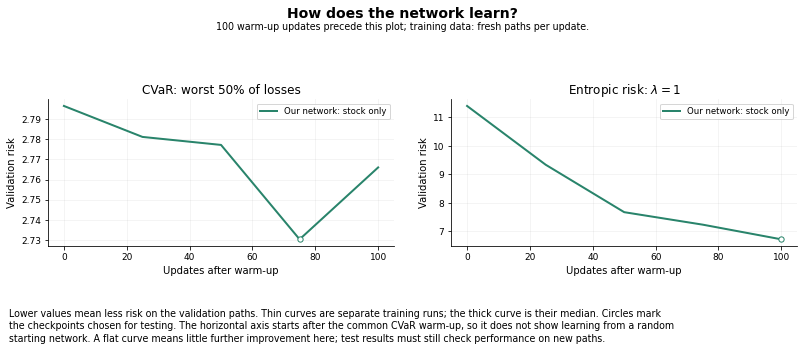

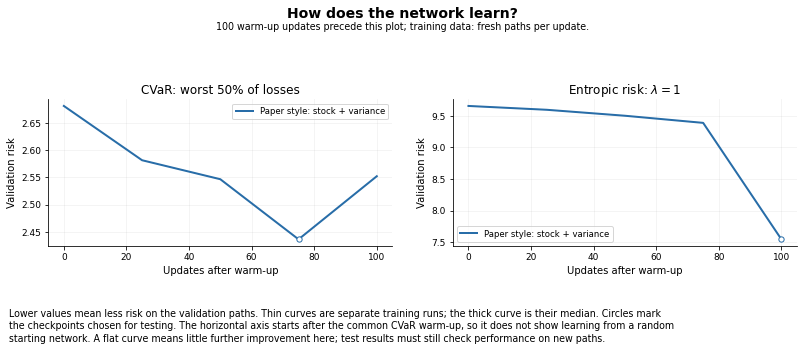

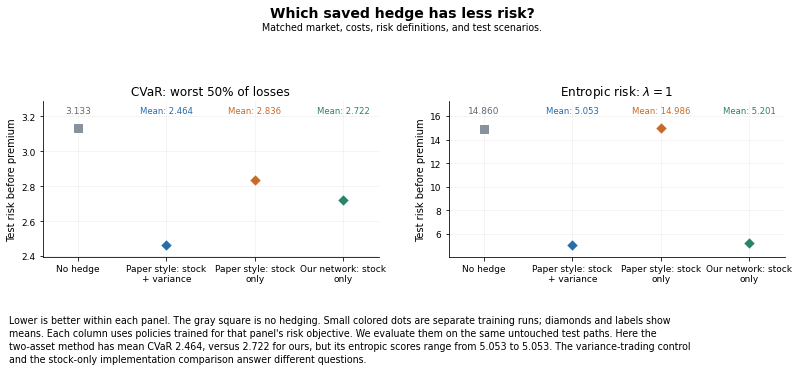

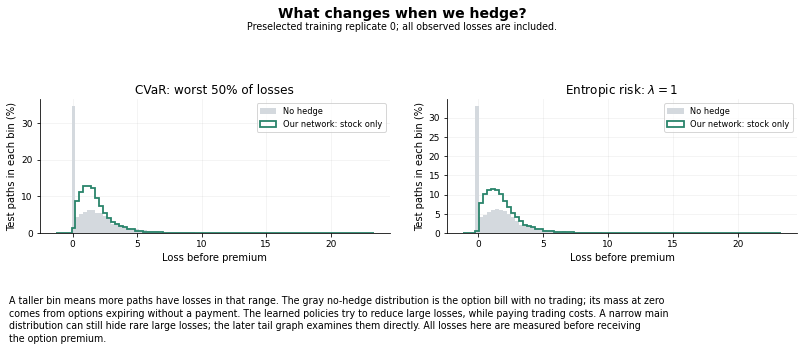

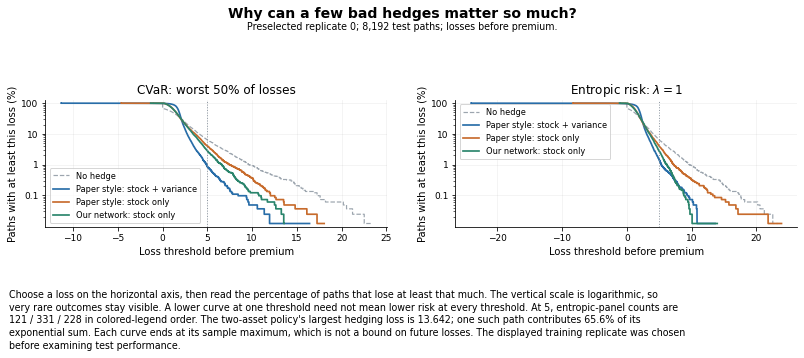

In [6]:
# Show how our model learned.
plots.plot_learning(ours)

# Show how the paper-style model learned.
plots.plot_learning(paper)

# Compare the test risk of all three models.
plots.plot_risk([paper, control, ours])

# Examine the loss distribution for our model.
plots.plot_losses(ours)

# Compare the frequencies of large losses.
plots.plot_loss_tails([paper, control, ours])